# Phân cụm phân cấp — AGNES & DIANA (dữ liệu 1 chiều)

## Đề bài

Cho 5 điểm trên trục số:

$$A = 1,\quad B = 2,\quad C = 4,\quad D = 8,\quad E = 9$$

khoảng cách $d(x, y) = |x - y|$.

| Điểm | A | B | C | D | E |
|---|---|---|---|---|---|
| $x$ | 1 | 2 | 4 | 8 | 9 |

Ma trận khoảng cách (đúng như hình):

| $d$ | A | B | C | D | E |
|---|---|---|---|---|---|
| **A** | 0 | 1 | 3 | 7 | 8 |
| **B** | 1 | 0 | 2 | 6 | 7 |
| **C** | 3 | 2 | 0 | 4 | 5 |
| **D** | 7 | 6 | 4 | 0 | 1 |
| **E** | 8 | 7 | 5 | 1 | 0 |

Nhìn trục số thấy ngay **hai nhóm rõ rệt**: $\{A, B, C\}$ và $\{D, E\}$ — vì khoảng trống
$C \to D$ là 4 đơn vị, lớn hơn hẳn các khoảng còn lại (1, 1, 2, 1).

## Yêu cầu

1. **AGNES** — hướng **bottom-up** (gộp dần) theo tiêu chí Ward: mỗi bước gộp cặp cụm có
   $\Delta$WCSS nhỏ nhất.
2. **DIANA** — hướng **top-down** (tách dần), đúng kiểu cây trong hình minh hoạ
   (độ cao = đường kính cụm: 8, 3, 1, 1).
3. So sánh hai cây, **cắt cây tại $k = 2$** và kiểm tra xem có thu được $\{A,B,C\}$ và $\{D,E\}$ không.

Toàn bộ thuật toán được cài đặt "từ đầu" (from scratch) chỉ bằng `numpy` + `matplotlib`,
để nhìn rõ từng bước tính chứ không gọi thư viện có sẵn.

## 1. Tiêu chí Ward và hai hướng đi

Với một cụm $C$ gồm các điểm trên trục số, độ "phân tán" của cụm đo bằng tổng bình phương
độ lệch so với tâm (WCSS — *within-cluster sum of squares*):

$$\mathrm{WCSS}(C) = \sum_{x \in C} \left(x - \bar{x}_C\right)^2,
\qquad \bar{x}_C = \frac{1}{|C|}\sum_{x \in C} x$$

Khi **gộp** hai cụm $A$, $B$, phương sai nội cụm tăng thêm một lượng:

$$\Delta(A,B) = \mathrm{WCSS}(A \cup B) - \mathrm{WCSS}(A) - \mathrm{WCSS}(B)
= \frac{|A|\,|B|}{|A| + |B|}\left(\bar{x}_A - \bar{x}_B\right)^2 \;\ge 0$$

Đó chính là **khoảng cách Ward**. Ý nghĩa:

- $\Delta$ nhỏ ⇒ gộp "rẻ" ⇒ hai cụm nên gộp với nhau.
- $\Delta$ lớn ⇒ gộp làm phương sai tăng mạnh ⇒ hai cụm khác nhau thực sự.
- $\Delta$ được dùng làm **độ cao** của nút trên dendrogram (đơn vị: phương sai tăng thêm).

Với dữ liệu 1 chiều, mỗi cụm luôn là một **đoạn thẳng** trên trục số, nên cắt cây ở bất kỳ
mức nào cũng cho các cụm là các đoạn rời nhau — rất trực quan.

Hai hướng đi dùng hai thước đo khác nhau (nhưng trên dữ liệu rõ ràng thì cho cùng một cây):

| | AGNES (bottom-up Ward) | DIANA (top-down) |
|---|---|---|
| Xuất phát | $n$ cụm, mỗi điểm một cụm | 1 cụm chứa tất cả |
| Mỗi bước | **gộp** 2 cụm có $\Delta$ nhỏ nhất | **tách** cụm có đường kính lớn nhất (splinter group) |
| Dừng | còn 1 cụm | mỗi điểm một cụm (hoặc đủ $k$ cụm) |
| Độ cao nút | $\Delta$WCSS lúc gộp | đường kính cụm bị tách |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from itertools import combinations
from pathlib import Path

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# ---------------------------------------------------------------------------
# DỮ LIỆU: 5 điểm trên trục số, d(x, y) = |x - y|
# ---------------------------------------------------------------------------
LABELS = np.array(list("ABCDE"))
X = np.array([1.0, 2.0, 4.0, 8.0, 9.0])
N = len(X)
D = np.abs(X[:, None] - X[None, :])          # ma trận khoảng cách 5 x 5

print("Toạ độ:", ", ".join(f"{l} = {x:g}" for l, x in zip(LABELS, X)))
print("\nMa trận khoảng cách d(x, y) = |x - y|:")
print("      " + "".join(f"{l:>6}" for l in LABELS))
for i, l in enumerate(LABELS):
    print(f"  {l}   " + "".join(f"{D[i, j]:6.0f}" for j in range(N)))

Toạ độ: A = 1, B = 2, C = 4, D = 8, E = 9

Ma trận khoảng cách d(x, y) = |x - y|:
           A     B     C     D     E
  A        0     1     3     7     8
  B        1     0     2     6     7
  C        3     2     0     4     5
  D        7     6     4     0     1
  E        8     7     5     1     0


## 2. Công cụ dùng chung

Mỗi cụm được biểu diễn bằng `Node` (danh sách chỉ số điểm, độ cao, 2 nút con) để có thể
dùng lại cho cả hai hướng và vẽ dendrogram.

In [2]:
# ---------------------------------------------------------------------------
# Các hàm tính toán cơ bản
# ---------------------------------------------------------------------------
def fmt_set(members):
    """Tên hiển thị của cụm: 'A' hoặc '{A,B,C}'."""
    members = tuple(sorted(members))
    if len(members) == 1:
        return str(LABELS[members[0]])
    return "{" + ",".join(str(LABELS[i]) for i in members) + "}"


def wcss(members):
    """Tổng bình phương độ lệch so với tâm cụm."""
    vals = X[list(members)]
    return float(((vals - vals.mean()) ** 2).sum())


def mean_of(members):
    """Tâm (trung bình) của cụm."""
    return float(X[list(members)].mean())


def ward_delta(a, b):
    """ΔWCSS khi gộp 2 cụm a, b = |a||b|/(|a|+|b|) * (mean_a - mean_b)^2."""
    na, nb = len(a), len(b)
    return na * nb / (na + nb) * (mean_of(a) - mean_of(b)) ** 2


@dataclass
class Node:
    """Một nút của cây phân cấp (lá = 1 điểm, nút trong = 1 cụm)."""
    members: tuple
    height: float = 0.0
    order: int = 0          # thứ tự bị tách (chỉ DIANA dùng)
    left: "Node | None" = None
    right: "Node | None" = None

    @property
    def is_leaf(self):
        return self.left is None

    @property
    def size(self):
        return len(self.members)

    @property
    def name(self):
        return fmt_set(self.members)


# ---------------------------------------------------------------------------
# Kiểm chứng: công thức Lance-Williams ở trên có đúng bằng
# WCSS(A∪B) - WCSS(A) - WCSS(B) không?
# ---------------------------------------------------------------------------
print("Kiểm chứng công thức Ward:")
print(f"  {'cặp':<8}{'ΔWCSS (công thức)':>20}{'WCSS(A∪B)-WCSS(A)-WCSS(B)':>30}")
for i, j in combinations(range(N), 2):
    a, b = (i,), (j,)
    lhs, rhs = ward_delta(a, b), wcss(a + b) - wcss(a) - wcss(b)
    print(f"  {LABELS[i]}-{LABELS[j]:<5}{lhs:>20.4f}{rhs:>30.4f}")
    assert abs(lhs - rhs) < 1e-12, "công thức phải khớp"

print(f"\nWCSS của cả 5 điểm = {wcss(tuple(range(N))):.4f}")

Kiểm chứng công thức Ward:
  cặp        ΔWCSS (công thức)     WCSS(A∪B)-WCSS(A)-WCSS(B)
  A-B                  0.5000                        0.5000
  A-C                  4.5000                        4.5000
  A-D                 24.5000                       24.5000
  A-E                 32.0000                       32.0000
  B-C                  2.0000                        2.0000
  B-D                 18.0000                       18.0000
  B-E                 24.5000                       24.5000
  C-D                  8.0000                        8.0000
  C-E                 12.5000                       12.5000
  D-E                  0.5000                        0.5000

WCSS của cả 5 điểm = 50.8000


## 3. Hướng 1 — AGNES (bottom-up Ward)

**AGNES** (*AGglomerative NESting*) là thuật toán gộp dần cổ điển; khi dùng tiêu chí Ward,
mỗi bước gộp cặp cụm có $\Delta$WCSS nhỏ nhất.

**Ý tưởng:** bắt đầu với 5 cụm đơn, mỗi bước gộp hai cụm có $\Delta$ Ward nhỏ nhất,
lặp đến khi chỉ còn một cụm.

```
clusters = [ {A}, {B}, {C}, {D}, {E} ]
while len(clusters) > 1:
    tìm cặp (U, V) có Δ(U, V) nhỏ nhất
    clusters.remove(U); clusters.remove(V); clusters.append(U ∪ V)
    ghi lại: độ cao = Δ(U, V), hai con = (U, V)
```

- Có 5 cụm ban đầu ⇒ đúng **4 bước** gộp.
- Nếu nhiều cặp cùng $\Delta$ (ở đây $A$-$B$ và $D$-$E$ đều bằng 0.5), ta chọn cặp có
  chỉ số nhỏ hơn. Với dữ liệu này cách chọn nào cũng cho cùng cây cuối cùng.
- Chi phí ngây thơ: $O(n^3)$ vì mỗi bước duyệt $O(n^2)$ cặp, có $n$ bước.

In [3]:
# ---------------------------------------------------------------------------
# BOTTOM-UP: gộp dần
# ---------------------------------------------------------------------------
active = [Node((i,)) for i in range(N)]      # ban đầu: mỗi điểm là 1 cụm
agg_steps = []                               # lịch sử gộp
n_pairs_total = 0                            # đếm số cặp đã xét (đo chi phí)

print("QUÁ TRÌNH GỘP (mỗi bước gộp 2 cụm có ΔWCSS nhỏ nhất)")
print("-" * 96)

while len(active) > 1:
    n_pairs_total += len(active) * (len(active) - 1) // 2

    # 1) duyệt mọi cặp cụm đang có, chọn Δ nhỏ nhất
    best = None
    for i, j in combinations(range(len(active)), 2):
        a, b = active[i], active[j]
        delta = ward_delta(a.members, b.members)
        key = (round(delta, 10), a.members, b.members)   # tie-break: chỉ số nhỏ
        if best is None or key < best[0]:
            best = (key, a, b, delta)

    _, a, b, delta = best
    left, right = sorted((a, b), key=lambda nd: nd.members[0])

    # 2) tạo cụm mới = hợp của 2 cụm, độ cao = ΔWCSS
    parent = Node(tuple(sorted(a.members + b.members)), height=delta, left=left, right=right)
    active = [nd for nd in active if nd is not a and nd is not b] + [parent]
    agg_steps.append((left, right, parent, delta))

    print(
        f"Bước {len(agg_steps)} | {left.name} + {right.name} -> {parent.name:<12}"
        f"| ΔWCSS = {delta:7.3f} | mean = {mean_of(parent.members):5.2f}"
        f" | WCSS = {wcss(parent.members):6.3f}"
    )

agg_root = active[0]                          # cụm gốc = toàn bộ 5 điểm

print("-" * 96)
print(f"Độ cao các nút (theo thứ tự gộp): {[round(s[2].height, 3) for s in agg_steps]}")
print(f"Tổng số cặp cụm đã xét: {n_pairs_total}")

QUÁ TRÌNH GỘP (mỗi bước gộp 2 cụm có ΔWCSS nhỏ nhất)
------------------------------------------------------------------------------------------------
Bước 1 | A + B -> {A,B}       | ΔWCSS =   0.500 | mean =  1.50 | WCSS =  0.500
Bước 2 | D + E -> {D,E}       | ΔWCSS =   0.500 | mean =  8.50 | WCSS =  0.500
Bước 3 | {A,B} + C -> {A,B,C}     | ΔWCSS =   4.167 | mean =  2.33 | WCSS =  4.667
Bước 4 | {A,B,C} + {D,E} -> {A,B,C,D,E} | ΔWCSS =  45.633 | mean =  4.80 | WCSS = 50.800
------------------------------------------------------------------------------------------------
Độ cao các nút (theo thứ tự gộp): [0.5, 0.5, 4.167, 45.633]
Tổng số cặp cụm đã xét: 20


### Công cụ vẽ

Hai hàm dưới đây dùng chung cho cả hai hướng:
`draw_axis` vẽ các điểm trên trục số (tô màu theo cụm), `draw_dendrogram` vẽ cây từ
cấu trúc `Node`, `cut_tree` cắt cây để lấy đúng $k$ cụm.

In [4]:
CLUSTER_COLORS = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e"]


def draw_axis(groups, ax, title=""):
    """Vẽ 5 điểm trên trục số, mỗi cụm một màu."""
    ax.axhline(0, color="#888888", lw=1)
    for k, g in enumerate(groups):
        for m in g:
            ax.plot(X[m], 0, "o", ms=13, mfc=CLUSTER_COLORS[k % len(CLUSTER_COLORS)],
                    mec="white", mew=1.6, zorder=3)
            ax.annotate(str(LABELS[m]), (X[m], 0), textcoords="offset points",
                        xytext=(0, 16), ha="center", fontsize=11, fontweight="bold")
    ax.set_yticks([])
    ax.set_ylim(-0.7, 0.7)
    ax.set_xlim(0, 10)
    ax.set_xticks(range(11))
    ax.set_xlabel("x")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)


def draw_dendrogram(node, ax, color="#2c7fb8", show_values=True):
    """Vẽ dendrogram từ cây Node (độ cao = ΔWCSS)."""
    order = []                                # thứ tự lá từ trái sang phải

    def collect(nd):
        if nd.is_leaf:
            order.append(nd.members[0])
        else:
            collect(nd.left)
            collect(nd.right)

    collect(node)
    xpos = {leaf: k for k, leaf in enumerate(order)}

    def x_of(nd):
        if nd.is_leaf:
            return xpos[nd.members[0]]
        return (x_of(nd.left) + x_of(nd.right)) / 2

    def rec(nd):
        if nd.is_leaf:
            return
        rec(nd.left)
        rec(nd.right)
        xl, xr, h = x_of(nd.left), x_of(nd.right), nd.height
        ax.plot([xl, xl], [nd.left.height, h], color=color, lw=1.8)
        ax.plot([xr, xr], [nd.right.height, h], color=color, lw=1.8)
        ax.plot([xl, xr], [h, h], color=color, lw=1.8)
        if show_values:
            ax.annotate(f"{h:.2f}", (x_of(nd), h), textcoords="offset points",
                        xytext=(0, 6), ha="center", fontsize=8, color=color)

    rec(node)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([LABELS[i] for i in order], fontsize=11)
    ax.set_ylabel("Độ cao = ΔWCSS")
    ax.set_xlabel("Điểm dữ liệu")
    ax.set_ylim(0, max(node.height, 1e-9) * 1.18)
    ax.set_xlim(-0.6, len(order) - 0.4)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def cut_tree(root, k):
    """Cắt cây để được đúng k cụm: tách dần nút có độ cao lớn nhất."""
    groups = [root]
    while len(groups) < k:
        node = max((g for g in groups if not g.is_leaf), key=lambda g: g.height)
        groups.remove(node)
        groups += [node.left, node.right]
    return tuple(sorted((g.members for g in groups), key=min))


def is_monotone(root):
    """Dendrogram hợp lệ khi độ cao không giảm từ lá lên gốc."""
    if root.is_leaf:
        return True
    return (root.height >= max(root.left.height, root.right.height) - 1e-9
            and is_monotone(root.left) and is_monotone(root.right))


print("Đã định nghĩa xong các hàm vẽ và cắt cây.")

Đã định nghĩa xong các hàm vẽ và cắt cây.


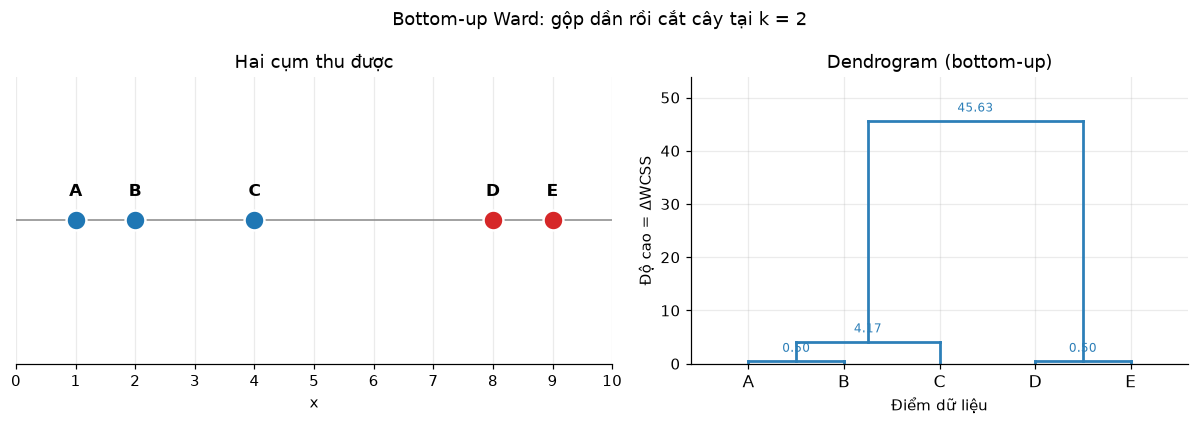

Cắt tại k = 2: ['{A,B,C}', '{D,E}']


In [5]:
groups_bottom = cut_tree(agg_root, 2)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.2, 1]})
fig.suptitle("Bottom-up Ward: gộp dần rồi cắt cây tại k = 2", fontsize=12)

draw_axis(groups_bottom, axes[0], "Hai cụm thu được")
draw_dendrogram(agg_root, axes[1])
axes[1].set_title("Dendrogram (bottom-up)")

fig.tight_layout()
fig.savefig(FIG_DIR / "ward_bottom_up.png", dpi=150)
plt.show()

print("Cắt tại k = 2:", [fmt_set(g) for g in groups_bottom])

## 4. Hướng 2 — DIANA (top-down)

DIANA (*DIvisive ANAlysis*, Kaufman & Rousseeuw) là thuật toán tách từ trên xuống cổ điển,
đúng kiểu cây trong hình minh hoạ. Hai đặc trưng:

**(a) Cách tách một cụm — "splinter group":**

1. Chọn điểm có **độ bất tương đồng trung bình** lớn nhất với các điểm còn lại → hạt giống
   của nhóm mới $S$ (splinter group).
2. Với mỗi điểm $j$ còn lại, tính khoảng cách trung bình tới $S$ và tới nhóm cũ $G$.
3. Chuyển điểm có chênh lệch $D(j,G) - D(j,S)$ **lớn nhất** sang $S$ nếu chênh lệch đó $> 0$
   (tức là $j$ gần nhóm mới hơn nhóm cũ), rồi lặp lại bước 2.
4. Dừng khi không còn điểm nào "gần nhóm mới hơn".

**(b) Chọn cụm để tách tiếp:** cụm có **đường kính** lớn nhất
($\text{diam}(C) = \max_{x,y \in C} d(x,y)$), và **độ cao của nút = đường kính của cụm bị tách**.
Đó là lý do cây trong hình ghi **8, 3, 1, 1**:

| Cụm bị tách | Đường kính | Lần tách |
|---|---|---|
| $\{A,B,C,D,E\}$ | $9 - 1 = 8$ | 1 |
| $\{A,B,C\}$ | $4 - 1 = 3$ | 2 |
| $\{A,B\}$ | $2 - 1 = 1$ | 3 |
| $\{D,E\}$ | $9 - 8 = 1$ | 4 |

Ở dữ liệu này DIANA cho **đúng cây trong hình**: tách lần lượt
$\{A,B,C\} \mid \{D,E\}$, rồi $\{A,B\} \mid \{C\}$, rồi $A \mid B$, rồi $D \mid E$.

> AGNES đo độ cao bằng **ΔWCSS** còn DIANA đo bằng **đường kính**, nên hai cây có cùng hình dạng
> nhưng **trục độ cao khác nhau** (45.63/4.17/0.50 so với 8/3/1/1). Đây chính là chỗ dễ nhầm.

In [6]:
# ---------------------------------------------------------------------------
# DIANA: "splinter group" + đường kính cụm
# ---------------------------------------------------------------------------
def diameter(members):
    """Đường kính cụm = khoảng cách lớn nhất giữa 2 điểm trong cụm."""
    idx = list(members)
    if len(idx) < 2:
        return 0.0
    return float(max(D[i, j] for a, i in enumerate(idx) for j in idx[a + 1:]))


def avg_dissim(i, group):
    """Độ bất tương đồng trung bình từ điểm i tới các điểm khác trong group."""
    others = [j for j in group if j != i]
    return float(np.mean([D[i, j] for j in others])) if others else 0.0


def diana_split(members):
    """Tách 1 cụm theo DIANA -> (nhóm mới, nhóm cũ, hạt giống, các bước chuyển)."""
    members = tuple(sorted(members))

    # (1) hạt giống = điểm "xa cách" nhất với phần còn lại
    seed = max(members, key=lambda i: (round(avg_dissim(i, members), 12), i))
    splinter, rest = [seed], [i for i in members if i != seed]
    moves = []

    # (2)-(4) chuyển dần những điểm gần nhóm mới hơn nhóm cũ
    while len(rest) > 1:
        scores = {}
        for j in rest:
            d_s = float(np.mean([D[j, s] for s in splinter]))
            d_g = float(np.mean([D[j, k] for k in rest if k != j]))
            scores[j] = d_g - d_s                  # > 0 nghĩa là gần nhóm mới hơn
        j = max(scores, key=lambda k: (round(scores[k], 12), -k))
        if scores[j] <= 1e-12:
            break
        moves.append((j, scores[j]))
        splinter.append(j)
        rest.remove(j)

    return tuple(sorted(splinter)), tuple(sorted(rest)), seed, moves


print("Độ bất tương đồng trung bình tới 4 điểm còn lại (dùng chọn hạt giống lần 1):")
for i in range(N):
    print(f"  {LABELS[i]}: {avg_dissim(i, tuple(range(N))):.2f}")

diana_root = Node(tuple(range(N)))
open_clusters = [diana_root]
diana_steps = []

while True:
    candidates = [nd for nd in open_clusters if nd.size > 1]
    if not candidates:
        break

    # chọn cụm có ĐƯỜNG KÍNH lớn nhất (hòa: cụm lớn hơn, rồi chỉ số nhỏ hơn)
    nd = max(candidates, key=lambda x: (round(diameter(x.members), 12), x.size, -x.members[0]))
    a, b, seed, moves = diana_split(nd.members)
    a, b = sorted((a, b), key=lambda t: t[0])     # hiển thị nhóm bên trái trước

    nd.order = len(diana_steps) + 1
    nd.height = diameter(nd.members)             # độ cao = đường kính cụm bị tách
    nd.left, nd.right = sorted((Node(a), Node(b)), key=lambda x: x.members[0])
    open_clusters.remove(nd)
    open_clusters += [nd.left, nd.right]
    diana_steps.append(nd)

    print(f"\nLần {nd.order} | tách {nd.name:<12} (đường kính {nd.height:g})"
          f" -> {fmt_set(a):<7} | {fmt_set(b):<7} | hạt giống {LABELS[seed]}")
    for j, score in moves:
        print(f"          chuyển {LABELS[j]} sang nhóm mới (gần nhóm mới hơn {score:.2f})")

print("\nĐộ cao các nút:", [(nd.name, nd.height) for nd in diana_steps])

Độ bất tương đồng trung bình tới 4 điểm còn lại (dùng chọn hạt giống lần 1):
  A: 4.75
  B: 4.00
  C: 3.50
  D: 4.50
  E: 5.25

Lần 1 | tách {A,B,C,D,E}  (đường kính 8) -> {A,B,C} | {D,E}   | hạt giống E
          chuyển D sang nhóm mới (gần nhóm mới hơn 4.67)

Lần 2 | tách {A,B,C}      (đường kính 3) -> {A,B}   | C       | hạt giống C

Lần 3 | tách {A,B}        (đường kính 1) -> A       | B       | hạt giống B

Lần 4 | tách {D,E}        (đường kính 1) -> D       | E       | hạt giống E

Độ cao các nút: [('{A,B,C,D,E}', 8.0), ('{A,B,C}', 3.0), ('{A,B}', 1.0), ('{D,E}', 1.0)]


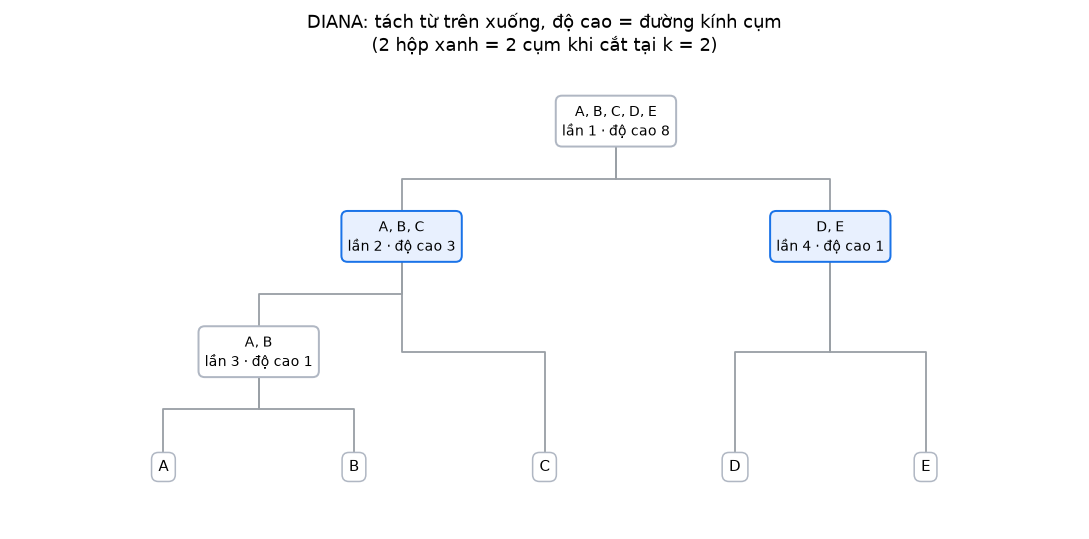

Cắt tại k = 2: ['{A,B,C}', '{D,E}']


In [7]:
def draw_box_tree(root, ax, highlight=()):
    """Vẽ cây phân cấp dạng hộp (kiểu hình minh hoạ DIANA)."""
    xpos, depth, leaves = {}, {}, []

    def collect(nd, d=0):
        depth[id(nd)] = d
        if nd.is_leaf:
            xpos[id(nd)] = len(leaves)
            leaves.append(nd)
        else:
            collect(nd.left, d + 1)
            collect(nd.right, d + 1)
            xpos[id(nd)] = (xpos[id(nd.left)] + xpos[id(nd.right)]) / 2

    collect(root)
    max_depth = max(depth[id(leaf)] for leaf in leaves)   # mọi lá xếp cùng hàng dưới

    def y_of(nd):
        return -0.85 * (max_depth if nd.is_leaf else depth[id(nd)])

    nodes = []

    def walk(nd):
        nodes.append(nd)
        if not nd.is_leaf:
            walk(nd.left)
            walk(nd.right)

    walk(root)

    for nd in nodes:                        # vẽ đường nối trước, hộp che lên trên
        if nd.is_leaf:
            continue
        x0, y0 = xpos[id(nd)], y_of(nd)
        for ch in (nd.left, nd.right):
            x1, y1 = xpos[id(ch)], y_of(ch)
            ym = (y0 + y1) / 2
            ax.plot([x0, x0, x1, x1], [y0 - 0.1, ym, ym, y1 + 0.1],
                    color="#9aa0a6", lw=1.2, zorder=1)

    for nd in nodes:
        x, y = xpos[id(nd)], y_of(nd)
        if nd.is_leaf:
            ax.text(x, y, str(LABELS[nd.members[0]]), ha="center", va="center",
                    fontsize=10, zorder=2,
                    bbox=dict(boxstyle="round,pad=0.45", fc="white", ec="#b0b7c3", lw=1))
        else:
            on = any(nd is h for h in highlight)
            names = ", ".join(str(LABELS[i]) for i in nd.members)
            ax.text(x, y, f"{names}\nlần {nd.order} · độ cao {nd.height:g}",
                    ha="center", va="center", fontsize=9, linespacing=1.4, zorder=2,
                    bbox=dict(boxstyle="round,pad=0.45",
                              fc="#e8f0fe" if on else "white",
                              ec="#1a73e8" if on else "#b0b7c3", lw=1.3))

    ax.set_xlim(-0.8, len(leaves) - 0.2)
    ax.set_ylim(-0.85 * max_depth - 0.45, 0.45)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(10, 5))
draw_box_tree(diana_root, ax, highlight=(diana_root.left, diana_root.right))
ax.set_title("DIANA: tách từ trên xuống, độ cao = đường kính cụm\n"
             "(2 hộp xanh = 2 cụm khi cắt tại k = 2)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "diana_tree.png", dpi=160)
plt.show()

print("Cắt tại k = 2:", [fmt_set(g) for g in cut_tree(diana_root, 2)])

## 5. So sánh hai cây

Cắt cả hai cây tại cùng số cụm $k$ rồi so sánh. Ngoài ra kiểm tra thêm:

- Cách cắt tại $k=2$ có trùng với **cách chia 2 cụm tối ưu theo WCSS** (duyệt đủ 15 cách chia) không.
- Cây có **hợp lệ** không (độ cao không giảm từ lá lên gốc).
- **Độ cao** của cùng một nút trên hai cây — để thấy rõ hai thang đo khác nhau.

> **Về "đường cắt":** với cây AGNES ở bài này, mức gộp lớn nhất *bên dưới* gốc là 4.17 còn lần
> gộp cuối là 45.63, nên **mọi** ngưỡng $h \in (4.17;\;45.63)$ đều cho đúng 2 cụm. Không có
> ngưỡng nào là "đúng" duy nhất — hình chỉ tô cả vùng đó thay vì bịa ra một con số cụ thể.

In [8]:
print(f"{'k':<4}{'AGNES (Ward)':<30}{'DIANA':<30}{'giống nhau?'}")
print("-" * 80)
for k in range(1, N + 1):
    ga = cut_tree(agg_root, k)
    gd = cut_tree(diana_root, k)
    print(f"{k:<4}{str([fmt_set(g) for g in ga]):<30}{str([fmt_set(g) for g in gd]):<30}"
          f"{'có' if ga == gd else 'KHÔNG'}")

k = 2
groups_bottom = cut_tree(agg_root, k)
assert groups_bottom == cut_tree(diana_root, k) == ((0, 1, 2), (3, 4))

print(f"\nCắt tại k = {k}: {fmt_set(groups_bottom[0])} và {fmt_set(groups_bottom[1])}"
      "  -> đúng như hình.")

# --- cùng một nút, hai thang đo độ cao ---
def find_node(root, members):
    """Tìm nút có đúng tập điểm members trong cây."""
    target = tuple(sorted(members))
    if root.members == target:
        return root
    if root.is_leaf:
        return None
    return find_node(root.left, members) or find_node(root.right, members)


print(f"\n{'nút':<10}{'AGNES (ΔWCSS)':>16}{'DIANA (đường kính)':>22}")
print("-" * 48)
for members, label in [((0, 1, 2, 3, 4), "cả 5 điểm"), ((0, 1, 2), "{A,B,C}"),
                       ((0, 1), "{A,B}"), ((3, 4), "{D,E}")]:
    print(f"{label:<10}{find_node(agg_root, members).height:>16.2f}"
          f"{find_node(diana_root, members).height:>22g}")

# --- kiểm chứng với cách chia 2 cụm tối ưu theo WCSS ---
def bipartitions(members):
    """Sinh mọi cách chia members thành 2 phần khác rỗng (mỗi cách xuất hiện 1 lần)."""
    items = list(members)
    m = len(items)
    for mask in range(1, 2 ** (m - 1)):        # cố định bit 0 = 0 để tránh trùng cặp bù
        a = tuple(items[i] for i in range(m) if mask >> i & 1)
        b = tuple(items[i] for i in range(m) if not mask >> i & 1)
        yield a, b


best = min(((wcss(a) + wcss(b), a, b) for a, b in bipartitions(tuple(range(N)))),
           key=lambda t: t[0])
print(f"\nTối ưu toàn cục khi chia 2 cụm (duyệt đủ 15 cách): "
      f"WCSS = {best[0]:.4f} với {fmt_set(best[1])} | {fmt_set(best[2])}")
print(f"WCSS của cách cắt cây tại k = 2: {sum(wcss(g) for g in groups_bottom):.4f}")

# --- kiểm tra thứ tự độ cao trên cả hai cây ---
for name, root in [("AGNES", agg_root), ("DIANA", diana_root)]:
    print(f"{name:<14}: {'hợp lệ' if is_monotone(root) else 'KHÔNG hợp lệ'}"
          " (độ cao không giảm từ lá lên gốc)")

k   AGNES (Ward)                  DIANA                         giống nhau?
--------------------------------------------------------------------------------
1   ['{A,B,C,D,E}']               ['{A,B,C,D,E}']               có
2   ['{A,B,C}', '{D,E}']          ['{A,B,C}', '{D,E}']          có
3   ['{A,B}', 'C', '{D,E}']       ['{A,B}', 'C', '{D,E}']       có
4   ['{A,B}', 'C', 'D', 'E']      ['{A,B}', 'C', 'D', 'E']      có
5   ['A', 'B', 'C', 'D', 'E']     ['A', 'B', 'C', 'D', 'E']     có

Cắt tại k = 2: {A,B,C} và {D,E}  -> đúng như hình.

nút          AGNES (ΔWCSS)    DIANA (đường kính)
------------------------------------------------
cả 5 điểm            45.63                     8
{A,B,C}               4.17                     3
{A,B}                 0.50                     1
{D,E}                 0.50                     1

Tối ưu toàn cục khi chia 2 cụm (duyệt đủ 15 cách): WCSS = 5.1667 với {A,B,C} | {D,E}
WCSS của cách cắt cây tại k = 2: 5.1667
AGNES         : hợp lệ (độ cao khôn

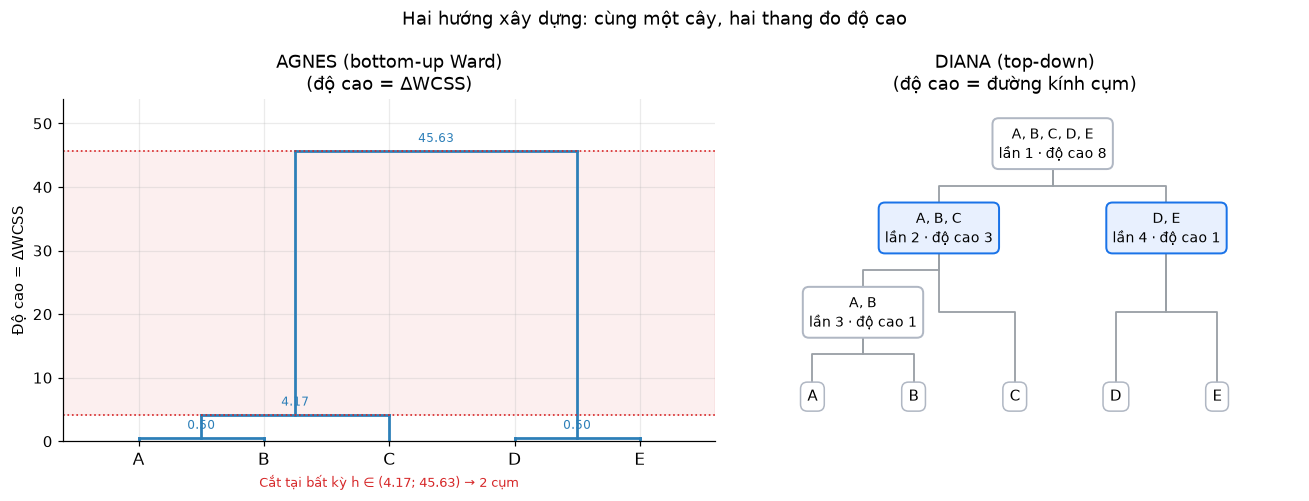

In [9]:
# --- vẽ hai cây cạnh nhau: cùng topology, khác thang đo độ cao ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})

draw_dendrogram(agg_root, axes[0], color="#2c7fb8")
# Ngưỡng cắt: MỌI h trong (mức gộp lớn nhất dưới gốc, độ cao gốc) đều cho 2 cụm.
lower = max(agg_root.left.height, agg_root.right.height)   # mức gộp lớn nhất bên dưới gốc
upper = agg_root.height                                    # lần gộp cuối (tạo 1 cụm)
axes[0].axhspan(lower, upper, color="#d62728", alpha=0.07, zorder=0)
for h in (lower, upper):
    axes[0].axhline(h, color="#d62728", ls=":", lw=1.1)
axes[0].set_xlabel(f"Cắt tại bất kỳ h ∈ ({lower:.2f}; {upper:.2f}) → 2 cụm",
                   color="#d62728", fontsize=8.5)
axes[0].set_title("AGNES (bottom-up Ward)\n(độ cao = ΔWCSS)")

draw_box_tree(diana_root, axes[1], highlight=(diana_root.left, diana_root.right))
axes[1].set_title("DIANA (top-down)\n(độ cao = đường kính cụm)")

fig.suptitle("Hai hướng xây dựng: cùng một cây, hai thang đo độ cao", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "ward_so_sanh.png", dpi=150)
plt.show()

## 6. Kết luận

### 6.1. Vì sao hai cây "giống nhau"?

Vì **topology của cây do dữ liệu quyết định**, không do hướng đi. Khoảng trống
$C \to D = 4$ lớn hơn hẳn các khoảng còn lại (1, 1, 2, 1), nên cả hai hướng đều ưu tiên
để $\{A,B,C\}$ và $\{D,E\}$ tách/gộp sau cùng. Trên dữ liệu 1 chiều "sạch" này:

- AGNES (bottom-up) và DIANA (top-down) cho **cùng topology** và **cùng thứ tự** tách/gộp;
- khác nhau chỉ ở **thang đo độ cao** ghi trên cây:

| Nút | AGNES (ΔWCSS) | DIANA (đường kính) |
|---|---|---|
| cả 5 điểm | 45.63 | 8 |
| $\{A,B,C\}$ | 4.17 | 3 |
| $\{A,B\}$ | 0.50 | 1 |
| $\{D,E\}$ | 0.50 | 1 |

- **ΔWCSS** đo "phương sai tăng thêm khi gộp": rất nhỏ với cặp sát nhau (0.5) và bùng lên
  ở lần gộp cuối (45.63).
- **Đường kính** đo "khoảng cách xa nhất trong cụm", đúng bằng độ dài đoạn thẳng chứa cụm
  (8, 3, 1, 1) — nên cây DIANA trông "khác" nhưng vẫn là cùng một cây.

### 6.2. Diễn biến trên dữ liệu này

| Bước | AGNES (gộp) | DIANA (tách) | ΔWCSS / đường kính |
|---|---|---|---|
| 1 | $A + B \to \{A,B\}$ | $\{A,B,C,D,E\} \to \{A,B,C\} \mid \{D,E\}$ | 0.500 / 8 |
| 2 | $D + E \to \{D,E\}$ | $\{A,B,C\} \to \{A,B\} \mid C$ | 0.500 / 3 |
| 3 | $\{A,B\} + C \to \{A,B,C\}$ | $\{A,B\} \to A \mid B$ | 4.167 / 1 |
| 4 | $\{A,B,C\} + \{D,E\} \to$ tất cả | $\{D,E\} \to D \mid E$ | 45.633 / 1 |

DIANA tách đúng theo thứ tự ngược lại của AGNES, nhưng ghi độ cao là đường kính: 8 → 3 → 1 → 1
(khớp với hình minh hoạ: "lần 1 · độ cao 8", "lần 2 · độ cao 3", "lần 3 · độ cao 1",
"lần 4 · độ cao 1").

### 6.3. Cắt cây & kiểm chứng

- Cắt tại $k = 2$: $\{A,B,C\}$ và $\{D,E\}$ — cả hai cây đều cho cùng kết quả.
- Cắt tại $k = 3$: $\{A,B\}$, $\{C\}$, $\{D,E\}$.
- WCSS của cách cắt tại $k=2$ là $5.167$, trùng với giá trị nhỏ nhất khi duyệt toàn bộ 15 cách
  chia 2 cụm ⇒ với dữ liệu này AGNES tìm được cách chia tối ưu toàn cục.

### 6.4. Chi phí & mở rộng

- **AGNES**: $O(n^3)$ ngây thơ (mỗi bước duyệt $O(n^2)$ cặp, có $n$ bước), ổn với $n$ vừa.
- **DIANA**: mỗi lần tách chỉ cần $O(n^2)$ (không duyệt mọi cách chia) ⇒ dùng được với $n$
  lớn hơn nhiều.
- AGNES chỉ dùng tâm và kích thước cụm; DIANA dùng trực tiếp ma trận khoảng cách. Cả hai mở
  rộng sang 2 chiều bằng khoảng cách Euclid mà không phải đổi cấu trúc code.

---

### Cách chạy

```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
# mở notebook bằng VS Code / Jupyter rồi Run All,
# hoặc chạy không cần giao diện:
.\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace ward_clustering_1d.ipynb
```

Hình được lưu trong thư mục `figures/` để chèn vào báo cáo:
`ward_bottom_up.png`, `diana_tree.png`, `ward_so_sanh.png`.